In [2]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Check TensorFlow version and see if Kaggle assigned a GPU
print("TensorFlow Version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs Available:", len(gpus))

TensorFlow Version: 2.20.0
GPUs Available: 2


In [3]:
import os

BASE_DIR = ""

# Tell Python to search the Kaggle input folder
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'valid' in dirs:
        BASE_DIR = root
        break

print("The main dataset is located at:", BASE_DIR)

The main dataset is located at: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)


In [4]:
import tensorflow as tf

# 1. Connect the exact paths for training and testing
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")

# 2. Set the rules for the images
IMG_SIZE = (128, 128)
BATCH_SIZE = 64

# 3. Load the training data (the images the AI learns from)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

# 4. Load the validation data (the images used to test the AI)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

# 5. Check what the AI found
class_names = train_ds.class_names
print(f"Total number of diseases found: {len(class_names)}")

Found 70295 files belonging to 38 classes.


I0000 00:00:1788762731.234905     484 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788762731.237749     484 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 17572 files belonging to 38 classes.
Total number of diseases found: 38


In [5]:
# Speed up the data pipeline so the GPUs don't wait for images
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Data pipeline optimized for GPU!")

Data pipeline optimized for GPU!


In [ ]:
from tensorflow.keras import layers, models

# 1. Custom Activation Function (Swish)
def swish_activation(x):
    return x * tf.keras.activations.sigmoid(x)

# 2. Squeeze-and-Excitation (SE) Block
def squeeze_excite_block(inputs, filters, squeeze_ratio=0.25):
    # Calculate how much to compress the data
    squeeze_channels = max(1, int(filters * squeeze_ratio))
    
    # Squeeze: Compress the picture into a tiny summary
    x = layers.GlobalAveragePooling2D()(inputs)
    x = layers.Reshape((1, 1, filters))(x)
    
    # Excitation: Figure out which visual features are the most important
    x = layers.Dense(squeeze_channels, activation=swish_activation)(x)
    x = layers.Dense(filters, activation='sigmoid')(x)
    
    # Apply those important highlights back to the original image
    return layers.Multiply()([inputs, x])

print("EfficientNet internal tools created successfully!")

EfficientNet internal tools created successfully!


In [7]:
def mbconv_block(inputs, filters, expand_ratio):
    # 1. Expand Phase: Make the data wider to see more details
    expanded_filters = inputs.shape[-1] * expand_ratio
    x = layers.Conv2D(expanded_filters, (1, 1), padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation(swish_activation)(x)
    
    # 2. Depthwise Phase: Scan each color channel completely separately
    x = layers.DepthwiseConv2D((3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation(swish_activation)(x)
    
    # 3. Attention Phase: Use the flashlight tool we built in Cell 5
    x = squeeze_excite_block(x, expanded_filters)
    
    # 4. Project Phase: Compress the data back down to save memory
    x = layers.Conv2D(filters, (1, 1), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    
    # 5. Skip Connection: A shortcut to help the AI remember the original image
    if inputs.shape[-1] == filters:
        x = layers.Add()([inputs, x])
        
    return x

print("MBConv core building block created successfully!")

MBConv core building block created successfully!


In [8]:
# 1. The Input (The original leaf photo)
inputs = layers.Input(shape=(128, 128, 3))
x = layers.Rescaling(1./255)(inputs)

# 2. The Stem (Initial basic scan)
x = layers.Conv2D(32, (3, 3), strides=2, padding='same', use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(swish_activation)(x)

# 3. The Body (Stacking our custom MBConv blocks)
# We start small and gradually increase the 'filters' (brain power)
x = mbconv_block(x, filters=16, expand_ratio=1)
x = mbconv_block(x, filters=24, expand_ratio=6)
x = mbconv_block(x, filters=40, expand_ratio=6)
x = mbconv_block(x, filters=80, expand_ratio=6)

# 4. The Head (Final review of the data)
x = layers.Conv2D(1280, (1, 1), padding='same', use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(swish_activation)(x)

# 5. The Output (Making the final decision for the 38 diseases)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(38, activation='softmax')(x)

# 6. Finalize the Model
custom_efficientnet = models.Model(inputs, outputs)

custom_efficientnet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      1,024 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 64, 64,    │        288 │ activation_1[0][… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ activation_2[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 8)   │        264 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 32)  │        288 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 64, 64,    │          0 │ activation_2[0][… │
│                     │ 32)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │        512 │ multiply[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv2d_2[0][0]  

 Total params: 254,854 (995.52 KB)

 Trainable params: 249,862 (976.02 KB)

 Non-trainable params: 4,992 (19.50 KB)

In [9]:
# 1. Compile the AI: Give it a teacher, a scoring system, and a report card
custom_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 2. Safety Net 1: Stop training early if the AI stops getting smarter
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# 3. Safety Net 2: Slow down the learning speed if it gets stuck
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-5
)

print("Model compiled and safety rules are set!")

Model compiled and safety rules are set!


In [10]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

# 1. Load data with a safe batch size
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical", shuffle=True, seed=42
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical", shuffle=False
)

# 2. Use prefetch ONLY (removed .cache to prevent RAM overflow)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

# 3. Build stable built-in model
base_model = EfficientNetB0(input_shape=(128, 128, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(38, activation='softmax')
])

# 4. Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train safely
print("Starting stable training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-5)
    ]
)
print("Training complete!")

Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.
Starting stable training...
Epoch 1/10


2026-09-07 06:33:13.543204: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:33:13.676450: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:33:13.993913: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:33:14.134104: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:33:14.965748: E external/local_xla/xla/stream_

2195/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7493 - loss: 1.0528

2026-09-07 06:34:50.716829: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:34:50.849756: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:34:51.169316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:34:51.310371: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:34:51.450864: E external/local_xla/xla/stream_

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7494 - loss: 1.0524

2026-09-07 06:35:29.203450: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:35:29.336383: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:35:29.638092: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:35:29.779623: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-07 06:35:29.920375: E external/local_xla/xla/stream_

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 159s 60ms/step - accuracy: 0.8504 - loss: 0.5975 - val_accuracy: 0.9317 - val_loss: 0.2557 - learning_rate: 0.0010
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9231 - loss: 0.2649 - val_accuracy: 0.9452 - val_loss: 0.1864 - learning_rate: 0.0010
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 43s 20ms/step - accuracy: 0.9337 - loss: 0.2138 - val_accuracy: 0.9514 - val_loss: 0.1576 - learning_rate: 0.0010
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 43s 20ms/step - accuracy: 0.9411 - loss: 0.1870 - val_accuracy: 0.9570 - val_loss: 0.1391 - learning_rate: 0.0010
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 43s 20ms/step - accuracy: 0.9447 - loss: 0.1726 - val_accuracy: 0.9579 - val_loss: 0.1327 - learning_rate: 0.0010
Epoch 6/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 45s 20ms/step - accuracy: 0.9465 - loss: 0.1648 - val_accuracy: 0.9601 - val_loss: 0.1265 - learning_rate: 0.0010
Epoch 7/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9503

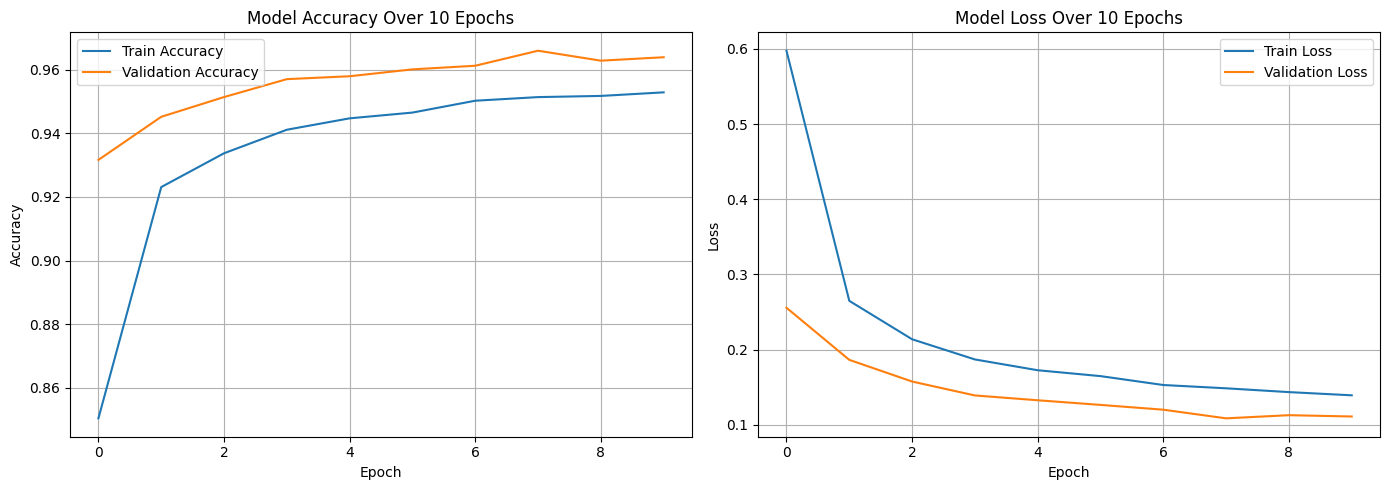

In [13]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Subplot
ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax1.set_title('Model Accuracy Over 10 Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss Subplot
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Validation Loss')
ax2.set_title('Model Loss Over 10 Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Testing with image: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test/TomatoHealthy4.JPG


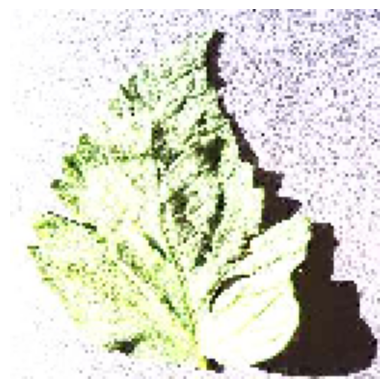

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Predicted Disease: Tomato___healthy
Confidence Score: 97.60%


In [24]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# 1. Automatically grab a sample image from your validation directory
subfolders = os.listdir(VALID_DIR)
sample_class_dir = os.path.join(VALID_DIR, subfolders[0])
sample_image_name = os.listdir(sample_class_dir)[0]
img_path = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test/TomatoHealthy4.JPG"
print("Testing with image:", img_path)

# 2. Load and display the image
img = image.load_img(img_path, target_size=(128, 128))
plt.imshow(img)
plt.axis('off')
plt.show()

# 3. Preprocess the image for the model
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# 4. Make a prediction using your trained model
predictions = model.predict(img_array)
predicted_index = np.argmax(predictions[0])
confidence = np.max(predictions[0]) * 100

# 5. Print out the result
predicted_disease = class_names[predicted_index]
print(f"Predicted Disease: {predicted_disease}")
print(f"Confidence Score: {confidence:.2f}%")

In [21]:
model.save("plant_disease_model.keras")

In [22]:
import keras
import numpy as np

loaded_model = keras.saving.load_model("plant_disease_model.keras")

# Verify predictions match
# x = keras.random.uniform((10, 128, 128, 3))
# assert np.allclose(model.predict(x), loaded_model.predict(x))
print("Model successfully saved and loaded as plant_disease_model.keras!")

Model successfully saved and loaded as plant_disease_model.keras!
